# GlucoGuide V3 · Sàng lọc tiểu đường từ các chỉ số

So sánh ba kiến trúc trên Pima để chọn một mạng dự đoán nhãn dương hoặc âm cho mẫu nghiên cứu. [Chạy form sàng lọc](https://glucoguide-giang254.vercel.app/#v3). Phần NHIS dành cho bài toán phân loại type khi mẫu đã được chẩn đoán.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'results/v3/dl_comparison.json').exists()), None)
if root is None:
    raise FileNotFoundError('Mở notebook từ thư mục project GlucoGuide.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from app.deep_study import MODEL_DIR, MODEL_LABELS, checkpoint, probabilities

study = json.loads((root / 'results/v3/dl_comparison.json').read_text())['datasets']
names = {'pima': 'Pima', 'early_stage': 'Early Stage'}
colors = {'mlp': '#00766c', 'cnn': '#b55430', 'transformer': '#6154a0'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 125,
                     'axes.spines.top': False, 'axes.spines.right': False})

## 1. So sánh ba kiến trúc cho sàng lọc

Demo dùng tám biến Pima của phụ nữ từ 21 tuổi. CNN 1D được chọn theo Macro-F1 validation trung bình trên ba seed. Early Stage là phép đối chiếu trên bảng hỏi triệu chứng.

Macro-F1 validation  Macro-F1 test  \
Dataset     Mô hình                                                          
Pima        CNN 1D                                    0.775          0.717   
            Transformer theo đặc trưng                0.767          0.706   
            MLP                                       0.757          0.721   
Early Stage MLP                                       0.849          0.944   
            CNN 1D                                    0.836          0.919   
            Transformer theo đặc trưng                0.823          0.901   

                                        Độ lệch chuẩn test  ROC-AUC test  \
Dataset     Mô hình                                                        
Pima        CNN 1D                                   0.026         0.806   
            Transformer theo đặc trưng               0.029         0.814   
            MLP                                      0.024         0.808   
Early Stage MLP                                      0.038         0.999   
            CNN 1D                                   0.012         0.991   
            Transformer theo đặc trưng               0.093         0.977   

                                       Form sàng lọc V3  
Dataset     Mô hình                                      
Pima        CNN 1D                                    ✓  
            Transformer theo đặc trưng                   
            MLP                                          
Early Stage MLP                                          
            CNN 1D                                       
            Transformer theo đặc trưng

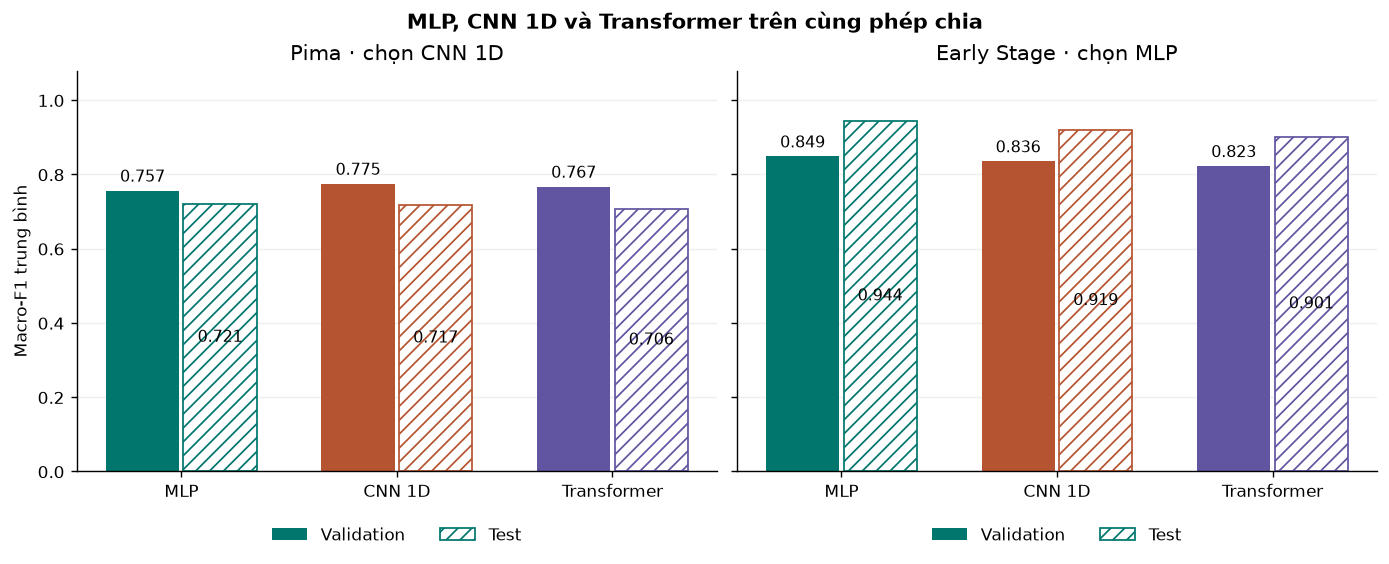

In [2]:
rows = []
for key, record in study.items():
    for family in record['ranking']:
        m = record['summary'][family]
        rows.append({'Dataset': names[key], 'Mô hình': m['label'],
                     'Macro-F1 validation': m['validation_f1'], 'Macro-F1 test': m['test_f1'],
                     'Độ lệch chuẩn test': m['test_f1_sd'], 'ROC-AUC test': m['test_auc'],
                     'Form sàng lọc V3': '✓' if key == 'pima' and family == record['ranking'][0] else ''})
display(pd.DataFrame(rows).set_index(['Dataset', 'Mô hình']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout='constrained')
short_labels = {'mlp':'MLP', 'cnn':'CNN 1D', 'transformer':'Transformer'}
for ax, (key, record) in zip(axes, study.items()):
    entries = list(record['summary'])
    x = np.arange(len(entries))
    validation = [record['summary'][f]['validation_f1'] for f in entries]
    test = [record['summary'][f]['test_f1'] for f in entries]
    selection = record['ranking'][0]
    m = ax.bar(x-.18, validation, .34, color=[colors[k] for k in entries], label='Validation')
    n = ax.bar(x+.18, test, .34, facecolor='white', edgecolor=[colors[k] for k in entries],
               hatch='///', label='Test')
    ax.bar_label(m, fmt='%.3f', padding=3, fontsize=9)
    ax.bar_label(n, fmt='%.3f', label_type='center', fontsize=9)
    ax.set(title=f'{names[key]} · chọn {short_labels[selection]}',
           xticks=x, xticklabels=[short_labels[k] for k in entries], ylim=(0, 1.08))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=.2)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.1), ncols=2, frameon=False)
axes[0].set_ylabel('Macro-F1 trung bình')
fig.suptitle('MLP, CNN 1D và Transformer trên cùng phép chia', weight='bold')
plt.show()

**Kết quả chọn theo validation** · CNN 1D dẫn trên Pima. MLP dẫn trên Early Stage. Trên test Pima, MLP có Macro-F1 0,721 và CNN có 0,717. Hai điểm test được công bố để thấy mức chênh lệch và vẫn áp dụng tiêu chí validation đã định trước.

## 2. So sánh ba kiến trúc trên NHIS

Tập [khảo sát công khai của CDC](https://www.cdc.gov/nchs/nhis/documentation/2024-nhis.html) có nhãn `DIBTYPE_A` do người tham gia thuật lại. Dùng năm 2022 để train, 2023 để chọn, 2024 để test. Đầu vào gồm tám biến: tuổi hiện tại, tuổi lúc được chẩn đoán, nhóm BMI, giới tính, tiền sử tăng huyết áp, tiền sử cholesterol cao, từng hút ít nhất 100 điếu thuốc lá và sức khỏe tự đánh giá. Đoạn dưới đọc kết quả đã lưu và chạy checkpoint V3 trên ba mẫu giả định. Đây là thí nghiệm phân loại hồi cứu trên nhóm đã được chẩn đoán. Mã không rõ ở năm biến bổ sung được điền bằng trung vị học từ train.

,Macro-F1 validation,"Macro-F1 test (ngưỡng 0,5)",Vai trò
Mô hình,,,
MLP,0.635,0.641,Đang dùng trên web
Transformer theo đặc trưng,0.630,0.629,Đối chứng
CNN 1D,0.616,0.632,Đối chứng


,Trường nhập,Mã biến NHIS
0,age,AGEP_A
1,age_at_diagnosis,DIBAGETC_A
2,bmi_category,BMICAT_A
3,sex,SEX_A
4,hypertension,HYPEV_A
5,high_cholesterol,CHLEV_A
6,smoked_100,SMKEV_A
7,general_health,PHSTAT_A


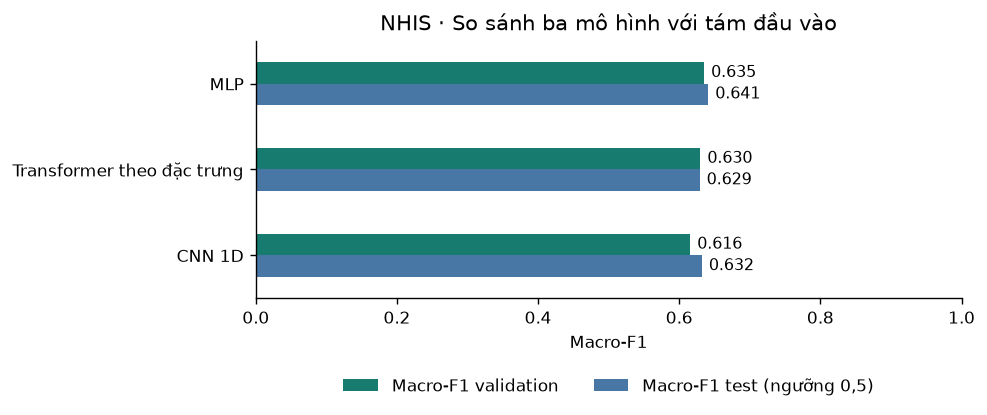

,Mẫu giả định,Điểm type 1,Nhãn
0,early_onset,0.956,type_1
1,later_onset,0.358,type_2
2,uncertain,0.782,undetermined


Hai ngưỡng trả nhãn: {'type_1': 0.9, 'type_2': 0.37}. Phần mẫu test có nhãn dự đoán: 74.1%.


In [3]:
from app import type_study

typed = type_study.results()
families = [typed['models'][name] for name in typed['ranking']]
comparison = pd.DataFrame([
    {'Mô hình': m['label'], 'Macro-F1 validation': m['validation_f1'],
     'Macro-F1 test (ngưỡng 0,5)': m['test']['macro_f1']}
    for m in families
]).set_index('Mô hình')
table = comparison.round(3).copy()
table['Vai trò'] = ['Đang dùng trên web' if family == typed['selected_family'] else 'Đối chứng'
                   for family in typed['ranking']]
display(table)
display(pd.DataFrame(typed['feature_columns'].items(), columns=['Trường nhập', 'Mã biến NHIS']))
axes = comparison.plot.barh(figsize=(8, 3.6), color=['#187b70', '#4876a5'])
axes.set(xlim=(0, 1), xlabel='Macro-F1', ylabel='', title='NHIS · So sánh ba mô hình với tám đầu vào')
axes.invert_yaxis()
for bars in axes.containers:
    axes.bar_label(bars, fmt='%.3f', padding=4, fontsize=9)
axes.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

rows = []
for key, sample in type_study.EXAMPLES.items():
    predicted = type_study.predict(**sample)
    assert predicted['label'] == typed['examples'][key]['label']
    np.testing.assert_allclose(predicted['type_1_score'], typed['examples'][key]['score'])
    rows.append({'Mẫu giả định': key, 'Điểm type 1': predicted['type_1_score'], 'Nhãn': predicted['label']})
display(pd.DataFrame(rows).round(3))
test = typed['guarded_test']
print(f"Hai ngưỡng trả nhãn: {typed['thresholds']}. Phần mẫu test có nhãn dự đoán: {test['coverage']:.1%}.")


**Kết quả.** Macro-F1 validation trung bình: MLP (0,635), Transformer (0,630) và CNN 1D (0,616). MLP seed 255 được triển khai sau khi kiểm tra có thể trả cả hai nhãn ở hai ngưỡng validation. Web chỉ nạp `nhis_type1_vs_type2_8f_mlp_seed255.npz`.

Macro-F1 test 2024 là 0,641 với tám biến và 0,644 với ba biến ở ngưỡng 0,5. Bản tám biến nhận thêm thông tin, với điểm tổng hợp tương đương trên lần chia này. Chế độ hai ngưỡng trả nhãn cho 74,1% mẫu, trong đó 42/63 dự đoán type 1 trùng nhãn khảo sát. Kết quả dùng cho demo nghiên cứu.

Để huấn luyện lại, chạy `python -m scripts.compare_diabetes_types data/raw/nhis` từ thư mục gốc.

## 3. Kiểm tra các checkpoint đối chứng và biểu đồ trên test

In [4]:
demo_rows, test_predictions = [], {}
for key, record in study.items():
    family, peer = record['ranking'][:2]
    weights, digest = checkpoint(key, family)
    other, _ = checkpoint(key, peer)
    test = record['test']
    frame = pd.read_csv(root / f'data/v2/{key}.csv').drop(columns=['target', 'split'])
    score = probabilities(family, frame.iloc[test['rows']].to_numpy(), weights)
    np.testing.assert_allclose(score, test['scores'][family], atol=2e-6, rtol=2e-6)
    demo = record['demo']
    values = pd.DataFrame([demo['values']], columns=frame.columns).to_numpy(dtype=float)
    result = float(probabilities(family, values, weights)[0])
    runner_up = float(probabilities(peer, values, other)[0])
    np.testing.assert_allclose(result, demo['scores'][family], atol=2e-6, rtol=2e-6)
    np.testing.assert_allclose(runner_up, demo['scores'][peer], atol=2e-6, rtol=2e-6)
    demo_rows.append({'Dataset': names[key], 'Mẫu': demo['row'],
                      'Mạng đã nạp': MODEL_LABELS[family], 'Điểm lớp dương': result,
                      'Mạng đối chứng': MODEL_LABELS[peer], 'Điểm đối chứng': runner_up})
    test_predictions[key] = (test['labels'], score)
    file = record['summary'][family]['checkpoint']['file']
    print(f"{names[key]} · {(MODEL_DIR / file).relative_to(root)} · SHA-256 {digest[:12]}…")
display(pd.DataFrame(demo_rows).set_index('Dataset').round(3))
print('Điểm từ checkpoint khớp với số liệu test đã lưu.')

Pima · models/v3/pima_cnn_seed255.npz · SHA-256 5e67d8ed2685…
Early Stage · models/v3/early_stage_mlp_seed254.npz · SHA-256 327b3ab6a352…


,Mẫu,Mạng đã nạp,Điểm lớp dương,Mạng đối chứng,Điểm đối chứng
Dataset,,,,,
Pima,73,CNN 1D,0.513,Transformer theo đặc trưng,0.265
Early Stage,84,MLP,0.733,CNN 1D,0.366


Điểm từ checkpoint khớp với số liệu test đã lưu.


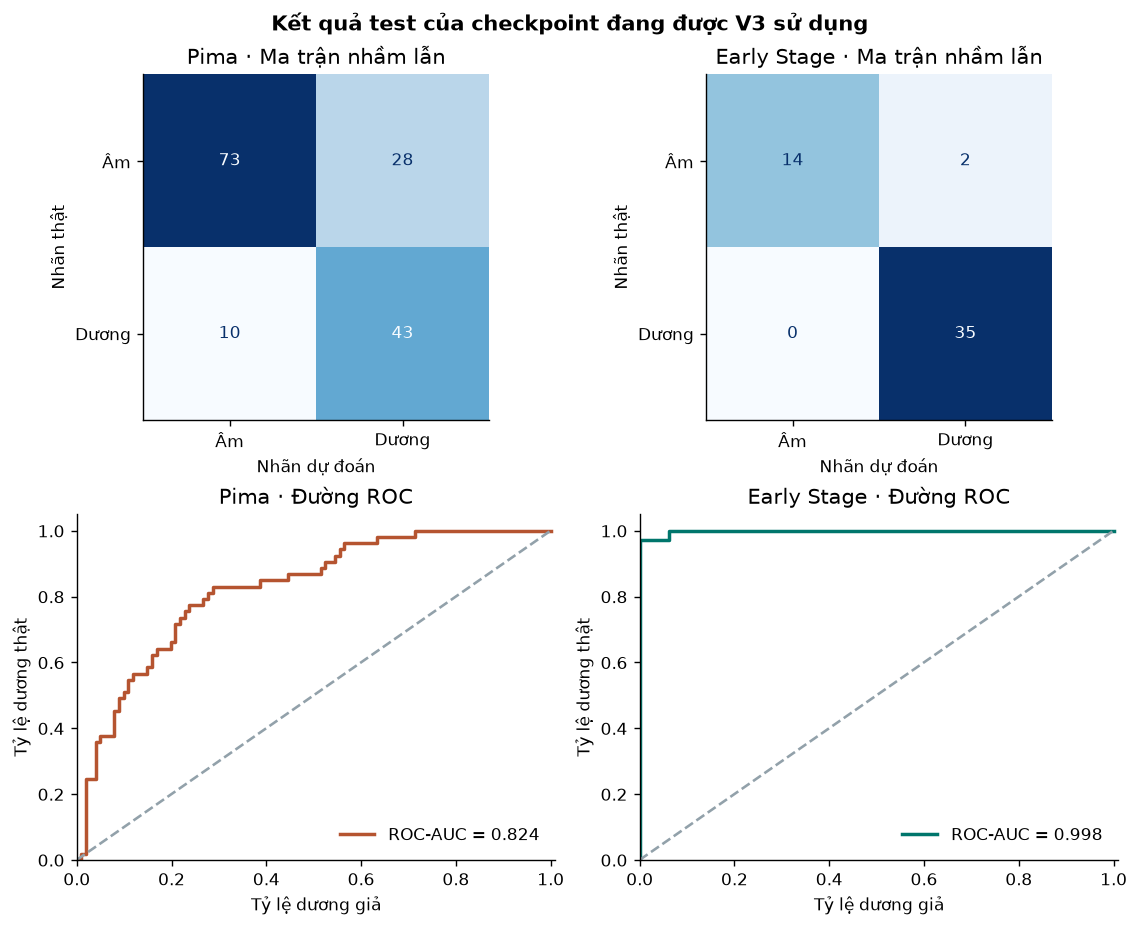

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7.3), layout='constrained')
for col, (key, (actual, score)) in enumerate(test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        actual, score >= .5, labels=[0, 1], display_labels=['Âm', 'Dương'],
        cmap='Blues', colorbar=False, ax=axes[0, col])
    axes[0, col].set(title=f'{names[key]} · Ma trận nhầm lẫn',
                     xlabel='Nhãn dự đoán', ylabel='Nhãn thật')
    fpr, tpr, _ = roc_curve(actual, score)
    family = study[key]['ranking'][0]
    axes[1, col].plot(fpr, tpr, color=colors[family], linewidth=2,
                     label=f'ROC-AUC = {roc_auc_score(actual, score):.3f}')
    axes[1, col].plot([0, 1], [0, 1], '--', color='#92a1aa')
    axes[1, col].set(title=f'{names[key]} · Đường ROC', xlabel='Tỷ lệ dương giả',
                     ylabel='Tỷ lệ dương thật', xlim=(0, 1.01), ylim=(0, 1.05))
    axes[1, col].legend(loc='lower right', frameon=False)
fig.suptitle('Kết quả test của checkpoint đang được V3 sử dụng', weight='bold')
plt.show()

## 4. Mở mã nguồn khi trình bày

- `scripts/compare_diabetes_types.py` huấn luyện ba kiến trúc và chọn checkpoint NHIS trên validation.
- `app/type_study.py` nạp checkpoint được chọn và tính điểm cho mẫu mới.
- `app/v2.py` nhận `POST /api/v2/type-predict` và chuyển qua Data, Prediction và Rule Agent.
- `app/v2.py` nhận `POST /api/v2/screening-predict`. `app/deep_study.py` nạp CNN 1D và trả nhãn nghiên cứu Pima.